# Regresión Cuantílica Conformalizada (CQR) en Predicción de Temperatura Crítica de Superconductores

## Sección 0: Título Ejecutivo, Objetivo, Hipótesis y Arquitectura del Sistema

Este cuaderno implementa una arquitectura de **regresión profunda con intervalos de predicción heterocedásticos y garantía de cobertura libre de distribución** mediante **Conformalized Quantile Regression (CQR)** *(Romano et al., 2019)* aplicada a la predicción de la temperatura crítica ($T_c$, en Kelvin) de materiales superconductores a partir de sus descriptores fisicoquímicos.

### Objetivo General
Desarrollar un modelo predictivo profundo que estime simultáneamente los cuantiles condicionales inferior, mediano y superior de la temperatura crítica $T_c$ y calibre dichos límites mediante **CQR** para garantizar una cobertura marginal exacta de muestra finita $\mathbb{P}ig(Y_{	ext{test}} \in C(X_{	ext{test}})ig) \ge 1 - lpha$ ($1 - lpha = 90\%$), logrando intervalos estrechos en regímenes de baja incertidumbre y bandas amplias en regímenes de alta dispersión física.

### Hipótesis de Trabajo
1. **Hipótesis de Cobertura Libre de Distribución**: Dado que las particiones de calibración $\mathcal{D}_{	ext{cal}}$ y prueba $\mathcal{D}_{	ext{test}}$ son **intercambiables** (*exchangeable*), el desplazamiento conformal $\hat{q}$ calculado sobre los *scores* de no-conformidad bidireccionales de **CQR** corregirá cualquier sesgo de sub-cobertura o sobre-cobertura del regresor neuronal, asegurando una cobertura empírica en `Test` de al menos $1 - lpha = 90.0\%$ sin imponer supuestos de normalidad ni homocedasticidad sobre los residuales.
2. **Hipótesis de Adaptabilidad Heterocedástica**: A diferencia del *Split Conformal Prediction* clásico basado en residuales absolutos $|y - \hat{\mu}(x)|$ —que produce intervalos de ancho constante $2\hat{q}$ en todo el espacio de características—, la combinación de una red neuronal entrenada con **Pinball Loss** y calibración **CQR** generará intervalos localmente adaptativos cuyo ancho variará significativamente según el régimen de temperatura crítica predicha $\hat{y}_{0.50}(x)$ (estrechos para superconductores convencionales de baja $T_c$ y amplios para cupratos/hidruros de alta $T_c$).

### Arquitectura del Sistema
1. **Dataset Fisicoquímico (`OpenML ID: 43174` — Superconductivty)**: $21,263$ compuestos superconductores caracterizados por $81$ descriptores derivados de propiedades atómicas (masa atómica, energía de primera ionización, radio atómico, valencia, afinidad electrónica y conductividad térmica).
2. **Particionado Estricto Cero-Contaminación**: División aleatoria estratificada `60% Train` / `20% Calibration` / `20% Test`, ajustando el estandarizador (`StandardScaler`) exclusivamente sobre `Train` para evitar fuga de información (*data leakage*).
3. **Arquitectura `QuantileMLP` & `PinballLoss` en PyTorch**: Perceptrón multicapa residual-regularizado (`Linear` $
ightarrow$ `BatchNorm1d` $
ightarrow$ `SiLU` $
ightarrow$ `Dropout`) entrenado para estimar conjuntamente los cuantiles $	au \in \{0.05, 0.50, 0.95\}$ con ordenamiento monótono garantizado en inferencia.
4. **Calibración Conformal CQR (Romano et al., 2019)**: Ajuste aditivo simétrico $\hat{q}$ sobre los cuantiles predichos, acoplado con restricción física de no-negatividad $T_c \ge 0	ext{ K}$.

### Referencias Académicas
- **Conformalized Quantile Regression (CQR)**: Romano, Y., Patterson, E., & Candès, E. J. (2019). *Conformalized Quantile Regression*. NeurIPS 2019.
- **Quantile Regression & Pinball Loss**: Koenker, R., & Bassett Jr, G. (1978). *Regression Quantiles*. Econometrica, 46(1), 33–50.
- **Superconductivity Dataset**: Hamidieh, K. (2018). *A data-driven statistical model for predicting the critical temperature of a superconductor*. Computational Materials Science, 154, 346–354.
- **Distribution-Free Predictive Inference**: Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J., & Wasserman, L. (2018). *Distribution-Free Predictive Inference for Regression*. JASA.

## Sección 1: Configuración Determinista, Carga de Datos y Particionado Estricto

Inicializamos las semillas aleatorias (`SEED = 42`), descargamos el conjunto de datos de superconductores desde **OpenML** (`data_id=43174`) y realizamos una partición estricta en tres subconjuntos disjuntos:
- **Entrenamiento (`60%`)**: Ajuste de pesos de la red neuronal cuantílica y cálculo de estadísticos de normalización ($\mu_{	ext{train}}, \sigma_{	ext{train}}$).
- **Calibración (`20%`)**: Conjunto reservado exclusivamente para estimar el factor de ajuste conformal $\hat{q}$.
- **Prueba (`20%`)**: Evaluación final de cobertura marginal y adaptabilidad local de los intervalos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1.1 Configuración global determinista
torch.manual_seed(42)
np.random.seed(42)

# 1.2 Descarga del dataset real de superconductores (21,263 materiales, 81 features químicas)
print("Descargando dataset de Superconductores desde OpenML...")
data = fetch_openml(data_id=43174, as_frame=True, parser="auto")
df = data.frame.dropna()

X = df.drop(columns=["critical_temp"]).values.astype(np.float32)
y = df["critical_temp"].values.astype(np.float32)  # Temperatura crítica en Kelvin (K)

# 1.3 División estricta en 3 conjuntos intercambiables: 60% Train | 20% Calibración | 20% Test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_calib, y_train, y_calib = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# Estandarización ajustada únicamente sobre Train (cero fuga de información)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_calib = scaler.transform(X_calib)
X_test  = scaler.transform(X_test)

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=256, shuffle=True
)

print(f"Dimensiones -> X_train: {X_train.shape} | X_calib: {X_calib.shape} | X_test: {X_test.shape}")

Descargando dataset de Superconductores desde OpenML...
Dimensiones -> X_train: (12757, 81) | X_calib: (4253, 81) | X_test: (4253, 81)


## Sección 2: Red Neuronal Multi-Cuantil (`QuantileMLP`) y Función de Pérdida Pinball

Para estimar simultáneamente el intervalo nominal central de nivel $1 - lpha = 90\%$ junto con la tendencia central, la red neuronal predice tres cuantiles condicionales $	au \in \{lpha/2, \, 0.50, \, 1 - lpha/2\} = \{0.05, \, 0.50, \, 0.95\}$:

$$\hat{f}(x) = ig(\hat{q}_{0.05}(x), \, \hat{q}_{0.50}(x), \, \hat{q}_{0.95}(x)ig)$$

### Función de Pérdida Pinball (Koenker & Bassett, 1978)
Para un cuantil objetivo $	au \in (0, 1)$ y error residual $e = y - \hat{q}_	au(x)$, la pérdida asimétrica *Pinball* se define como:

$$\mathcal{L}_	au(y, \hat{q}_	au(x)) = \maxig(	au (y - \hat{q}_	au(x)), \; (	au - 1)(y - \hat{q}_	au(x))ig) = egin{cases} 	au (y - \hat{q}_	au(x)) & 	ext{si } y \ge \hat{q}_	au(x) \ (1 - 	au)(\hat{q}_	au(x) - y) & 	ext{si } y < \hat{q}_	au(x) \end{cases}$$

Minimizar $rac{1}{|\mathcal{T}|}\sum_{	au \in \mathcal{T}} \mathcal{L}_	au(y, \hat{q}_	au(x))$ incentiva a la red a capturar directamente la heterocedasticidad condicional de $Y \mid X$. Adicionalmente, en inferencia ordenamos las salidas por fila (`np.sort`) para evitar el fenómeno de cruce de cuantiles (*quantile crossing*).

In [2]:
# 2.1 Arquitectura Perceptrón Multicapa para Regresión Cuantílica Conjunta
class QuantileMLP(nn.Module):
    def __init__(self, input_dim, num_quantiles=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.15),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.SiLU(),
            nn.Linear(128, 64),
            nn.SiLU(),
            nn.Linear(64, num_quantiles)
        )

    def forward(self, x):
        return self.net(x)

# 2.2 Implementación vectorizada de Pinball Loss Multi-Cuantil
class PinballLoss(nn.Module):
    def __init__(self, quantiles):
        super().__init__()
        self.quantiles = quantiles

    def forward(self, preds, target):
        target = target.unsqueeze(1)
        errors = target - preds
        losses = [
            torch.maximum(q * errors[:, i], (q - 1.0) * errors[:, i])
            for i, q in enumerate(self.quantiles)
        ]
        return torch.mean(torch.stack(losses, dim=1))

# 2.3 Entrenamiento del modelo
alpha = 0.10  # Objetivo: 90% de cobertura garantizada
quantiles = [alpha / 2, 0.50, 1.0 - alpha / 2]  # [0.05, 0.50, 0.95]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = QuantileMLP(input_dim=X_train.shape[1], num_quantiles=3).to(device)
criterion = PinballLoss(quantiles)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)

print(f"Entrenando Red Neuronal Cuantílica con Pinball Loss (Dispositivo: {device})...")
for epoch in range(35):
    model.train()
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(model(bx), by)
        loss.backward()
        optimizer.step()

def predict_quantiles(X_np):
    """Predice los cuantiles [0.05, 0.50, 0.95] garantizando monotonicidad por fila."""
    model.eval()
    with torch.no_grad():
        out = model(torch.from_numpy(X_np).to(device)).cpu().numpy()
    out = np.sort(out, axis=1)  # Garantizar q_0.05 <= q_0.50 <= q_0.95
    return out[:, 0], out[:, 1], out[:, 2]

Entrenando Red Neuronal Cuantílica con Pinball Loss (Dispositivo: cpu)...


## Sección 3: Calibración Conformal CQR y Evaluación en Test

Los cuantiles crudos $[\hat{q}_{lpha/2}(x), \, \hat{q}_{1-lpha/2}(x)]$ producidos por una red neuronal no ofrecen garantías formales de cobertura en muestra finita debido al error de aproximación y sobreajuste. **Conformalized Quantile Regression (CQR)** *(Romano et al., 2019)* corrige este problema midiendo qué tanto se desvía cada observación de calibración $Y_i$ fuera de su intervalo cuantílico predicho.

### Score de No-Conformidad Bidireccional CQR
Para cada punto de calibración $(X_i, Y_i) \in \mathcal{D}_{	ext{cal}}$, definimos el *score* firmado:

$$E_i = \max\Big(\hat{q}_{lpha/2}(X_i) - Y_i, \; Y_i - \hat{q}_{1-lpha/2}(X_i)\Big)$$

- Si $E_i > 0$, la observación $Y_i$ cayó **fuera** del intervalo crudo por una distancia de $E_i$ Kelvin.
- Si $E_i \le 0$, la observación $Y_i$ cayó **dentro** del intervalo crudo con un margen de holgura $|E_i|$.

Calculamos el factor de ajuste $\hat{q}$ como el cuantil empírico de orden $rac{\lceil (n+1)(1-lpha)
ceil}{n}$ sobre $\{E_1, \dots, E_n\}$, y construimos el intervalo conformalizado final (truncado inferiormente en $0	ext{ K}$ por restricción termodinámica):

$$C_{	ext{CQR}}(X_{	ext{test}}) = \Big[\maxig(0, \; \hat{q}_{lpha/2}(X_{	ext{test}}) - \hat{q}ig), \; \hat{q}_{1-lpha/2}(X_{	ext{test}}) + \hat{q}\Big]$$

Notablemente, si los intervalos crudos de la red neuronal ya son ligeramente conservadores, $\hat{q}$ tomará un **valor negativo** ($\hat{q} < 0$), contrayendo las bandas para mejorar la eficiencia sin sacrificar la garantía $\mathbb{P}(Y_{	ext{test}} \in C_{	ext{CQR}}(X_{	ext{test}})) \ge 1 - lpha$.

In [3]:
# ==============================================================================
# 3.1 CALIBRACIÓN CONFORMAL (CQR)
# ==============================================================================
calib_low, _, calib_high = predict_quantiles(X_calib)
scores = np.maximum(calib_low - y_calib, y_calib - calib_high)

n = len(y_calib)
q_level = np.ceil((n + 1) * (1 - alpha)) / n
q_hat = np.quantile(scores, q_level, method="higher")

print(f"Factor de ajuste conformal q_hat: {q_hat:+.2f} K")

# ==============================================================================
# 3.2 EVALUACIÓN EN TEST SET
# ==============================================================================
raw_low, test_mid, raw_high = predict_quantiles(X_test)
test_low  = np.maximum(0.0, raw_low - q_hat)
test_high = raw_high + q_hat

coverage  = np.mean((y_test >= test_low) & (y_test <= test_high))
widths    = test_high - test_low

print(f"Cobertura objetivo: {(1 - alpha)*100:.1f}%")
print(f"Cobertura real obtenida en Test (CQR + PyTorch): {coverage*100:.2f}%")
print(f"Ancho mínimo: {widths.min():.1f} K | Ancho promedio: {widths.mean():.1f} K | Ancho máximo: {widths.max():.1f} K")

Factor de ajuste conformal q_hat: -0.21 K
Cobertura objetivo: 90.0%
Cobertura real obtenida en Test (CQR + PyTorch): 90.20%
Ancho mínimo: 2.3 K | Ancho promedio: 36.7 K | Ancho máximo: 107.2 K


## Sección 4: Análisis Visual de Adaptabilidad Heterocedástica

Para demostrar empíricamente la ventaja de **CQR** frente a los intervalos de ancho constante propios del *Split Conformal Prediction* estándar, generamos una figura diagnóstica de dos paneles:
1. **Panel Izquierdo — Banda Conformal CQR sobre Muestra Ordenada**: Muestra $60$ materiales de prueba ordenados por su temperatura crítica mediana predicha $\hat{y}_{0.50}(x)$, evidenciando cómo la envolvente azul se expande dinámicamente en compuestos de alta temperatura crítica donde la física del estado sólido presenta mayor varianza.
2. **Panel Derecho — Distribución del Ancho del Intervalo por Régimen de $T_c$**: Diagramas de caja (*boxplots*) estratificados en intervalos de $10	ext{ K}$ comparados contra la línea roja punteada que representa el ancho fijo equivalente de un método homocedástico.

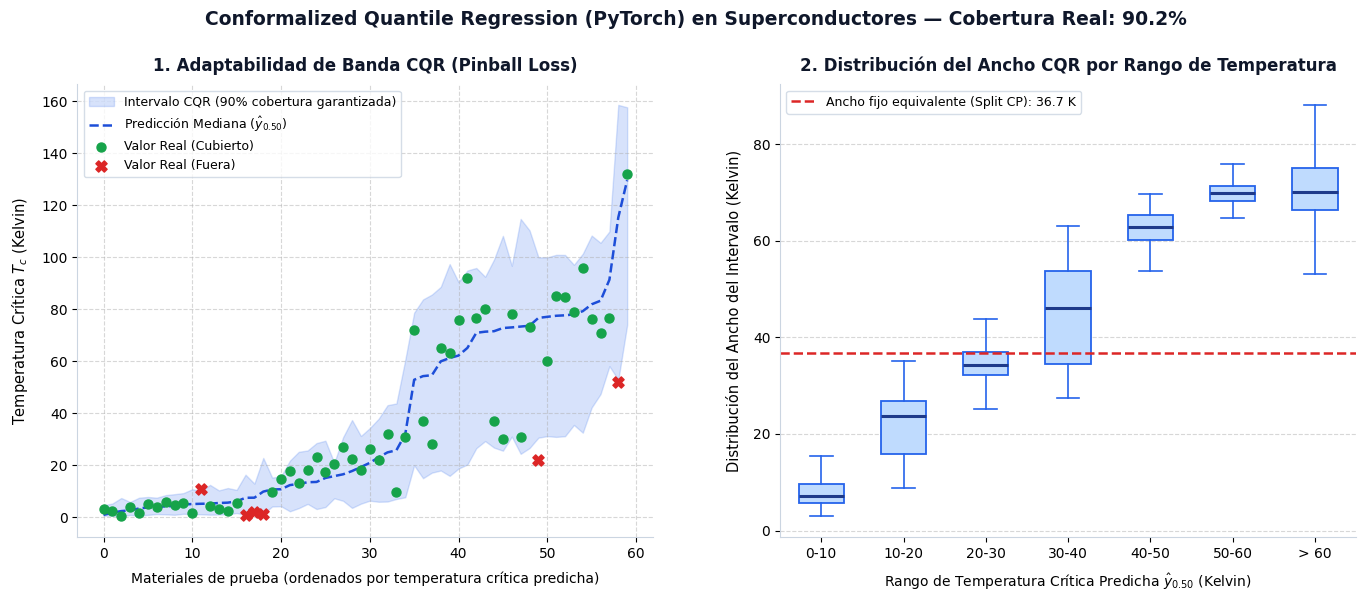

Gráfico guardado como 'cqr_pytorch_superconductores_boxplot.png'


In [4]:
# ==============================================================================
# 4. VISUALIZACIÓN: BANDA CQR + BOXPLOT DE ANCHOS POR RANGO DE TEMPERATURA (10 EN 10)
# ==============================================================================
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(y_test), size=60, replace=False)
order = np.argsort(test_mid[sample_idx])
idx_sorted = sample_idx[order]

x_axis      = np.arange(len(idx_sorted))
y_true_plot = y_test[idx_sorted]
low_plot    = test_low[idx_sorted]
high_plot   = test_high[idx_sorted]
mid_plot    = test_mid[idx_sorted]
inside      = (y_true_plot >= low_plot) & (y_true_plot <= high_plot)

plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "axes.edgecolor": "#cbd5e1"})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 6.2))
fig.subplots_adjust(wspace=0.22, top=0.84)

# --- Panel Izquierdo: Banda Conformal CQR ---
ax1.fill_between(
    x_axis, low_plot, high_plot,
    color="#2563eb", alpha=0.18,
    label=f"Intervalo CQR ({(1-alpha)*100:.0f}% cobertura garantizada)"
)
ax1.plot(x_axis, mid_plot, color="#1d4ed8", linestyle="--", linewidth=1.8, label="Predicción Mediana ($\\hat{y}_{0.50}$)")
ax1.scatter(x_axis[inside], y_true_plot[inside], color="#16a34a", s=42, zorder=4, label="Valor Real (Cubierto)")
ax1.scatter(x_axis[~inside], y_true_plot[~inside], color="#dc2626", s=65, marker="X", zorder=5, label="Valor Real (Fuera)")

ax1.set_xlabel("Materiales de prueba (ordenados por temperatura crítica predicha)", fontsize=10, labelpad=8)
ax1.set_ylabel("Temperatura Crítica $T_c$ (Kelvin)", fontsize=10.5, labelpad=8)
ax1.set_title("1. Adaptabilidad de Banda CQR (Pinball Loss)", fontsize=12, fontweight="bold", pad=10, color="#0f172a")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cbd5e1", fontsize=9)

# --- Panel Derecho: Boxplot de Anchos por Rango de 10 K (agrupando > 60 K) ---
bins = [0, 10, 20, 30, 40, 50, 60, np.inf]
bin_labels = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "> 60"]

binned_widths = []
valid_labels = []
for i in range(len(bins) - 1):
    mask = (test_mid >= bins[i]) & (test_mid < bins[i + 1])
    if np.sum(mask) > 0:
        binned_widths.append(widths[mask])
        valid_labels.append(bin_labels[i])

bp = ax2.boxplot(
    binned_widths,
    tick_labels=valid_labels,
    patch_artist=True,
    showfliers=False,  # Ocultar outliers extremos para mantener limpia la escala visual
    widths=0.55,
    boxprops=dict(facecolor="#bfdbfe", edgecolor="#2563eb", linewidth=1.3),
    medianprops=dict(color="#1e3a8a", linewidth=2.2),
    whiskerprops=dict(color="#2563eb", linewidth=1.2),
    capprops=dict(color="#2563eb", linewidth=1.2)
)

ax2.axhline(
    widths.mean(), color="#dc2626", linestyle="--", linewidth=1.8,
    label=f"Ancho fijo equivalente (Split CP): {widths.mean():.1f} K"
)

ax2.set_xlabel("Rango de Temperatura Crítica Predicha $\\hat{y}_{0.50}$ (Kelvin)", fontsize=10, labelpad=8)
ax2.set_ylabel("Distribución del Ancho del Intervalo (Kelvin)", fontsize=10.5, labelpad=8)
ax2.set_title("2. Distribución del Ancho CQR por Rango de Temperatura", fontsize=12, fontweight="bold", pad=10, color="#0f172a")
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="#cbd5e1", fontsize=9)

fig.suptitle(
    f"Conformalized Quantile Regression (PyTorch) en Superconductores — Cobertura Real: {coverage*100:.1f}%",
    fontsize=13.5, fontweight="bold", y=0.96, color="#0f172a"
)
plt.savefig("cqr_pytorch_superconductores_boxplot.png", dpi=220, bbox_inches="tight")
plt.show()
print("Gráfico guardado como 'cqr_pytorch_superconductores_boxplot.png'")